<a href="https://colab.research.google.com/github/Bilalabdulkadir/.github/blob/main/Week_4_Kickstarter_Statistical_Analysis_Plan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
kemical_kickstarter_projects_path = kagglehub.dataset_download('kemical/kickstarter-projects')

print('Data source import complete.')

100%|██████████| 36.8M/36.8M [00:01<00:00, 26.1MB/s]

Extracting files...


Data source import complete.


In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
import pandas as pd
import os

# Construct the correct path using the variable returned by kagglehub
csv_path = os.path.join(kemical_kickstarter_projects_path, 'ks-projects-201801.csv')

df = pd.read_csv(csv_path)

df.head()

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 378661 entries, 0 to 378660
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   ID                378661 non-null  int64  
 1   name              378657 non-null  object 
 2   category          378661 non-null  object 
 3   main_category     378661 non-null  object 
 4   currency          378661 non-null  object 
 5   deadline          378661 non-null  object 
 6   goal              378661 non-null  float64
 7   launched          378661 non-null  object 
 8   pledged           378661 non-null  float64
 9   state             378661 non-null  object 
 10  backers           378661 non-null  int64  
 11  country           378661 non-null  object 
 12  usd pledged       374864 non-null  float64
 13  usd_pledged_real  378661 non-null  float64
 14  usd_goal_real     378661 non-null  float64
dtypes: float64(5), int64(2), object(8)
memory usage: 43.3+ MB


In [6]:
df.describe()

,ID,goal,pledged,backers,usd pledged,usd_pledged_real,usd_goal_real
count,3.786610e+05,3.786610e+05,3.786610e+05,378661.000000,3.748640e+05,3.786610e+05,3.786610e+05
mean,1.074731e+09,4.908079e+04,9.682979e+03,105.617476,7.036729e+03,9.058924e+03,4.545440e+04
std,6.190862e+08,1.183391e+06,9.563601e+04,907.185035,7.863975e+04,9.097334e+04,1.152950e+06
min,5.971000e+03,1.000000e-02,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,1.000000e-02
25%,5.382635e+08,2.000000e+03,3.000000e+01,2.000000,1.698000e+01,3.100000e+01,2.000000e+03
50%,1.075276e+09,5.200000e+03,6.200000e+02,12.000000,3.947200e+02,6.243300e+02,5.500000e+03
75%,1.610149e+09,1.600000e+04,4.076000e+03,56.000000,3.034090e+03,4.050000e+03,1.550000e+04
max,2.147476e+09,1.000000e+08,2.033899e+07,219382.000000,2.033899e+07,2.033899e+07,1.663614e+08


In [7]:
df['state'].value_counts()

,count
state,
failed,197719
successful,133956
canceled,38779
undefined,3562
live,2799
suspended,1846


In [ ]:
import matplotlib.pyplot as plt

success_rate = df['state'].value_counts()

success_rate.plot(kind='bar')
plt.title('Kickstarter Project Outcomes')
plt.ylabel('Count')
plt.show()


## Initial Exploratory Findings

The Kickstarter dataset contains **378,661 projects** and **15 variables**, including project characteristics, funding information, campaign dates, and final project outcomes.

### Data Quality

Most variables contain complete information. However, the `usd pledged` variable contains some missing values, while the majority of variables have no missing observations. This suggests that the dataset is generally suitable for analysis, although missing values should be considered during any formal statistical testing.

### Summary Statistics

The summary statistics indicate substantial variation in campaign funding goals and pledged amounts. The large difference between the median and maximum values suggests that these variables are highly skewed and contain extreme outliers. This is common in crowdfunding data where a small number of projects raise exceptionally large amounts of money.

### Project Outcomes

The distribution of project outcomes shows that:

- Failed projects: 197,719
- Successful projects: 133,956
- Cancelled projects: 38,779
- Undefined projects: 3,562
- Live projects: 2,799
- Suspended projects: 1,846

The largest group consists of failed projects, followed by successful projects. For many research questions, it may be appropriate to focus only on completed projects (successful and failed) while excluding live, suspended, and undefined campaigns.

### Implications for Further Analysis

These initial findings suggest that project outcome (`state`) is a useful variable for analysis. Future investigation could examine whether project category, funding goals, campaign duration, or other characteristics are associated with the likelihood of campaign success.

The skewness observed in funding variables may also influence the choice of statistical tests, and non-parametric methods may be preferable where assumptions of normality are not met.


In [8]:
df['main_category'].value_counts()

,count
main_category,
Film & Video,63585
Music,51918
Publishing,39874
Games,35231
Technology,32569
Design,30070
Art,28153
Food,24602
Fashion,22816


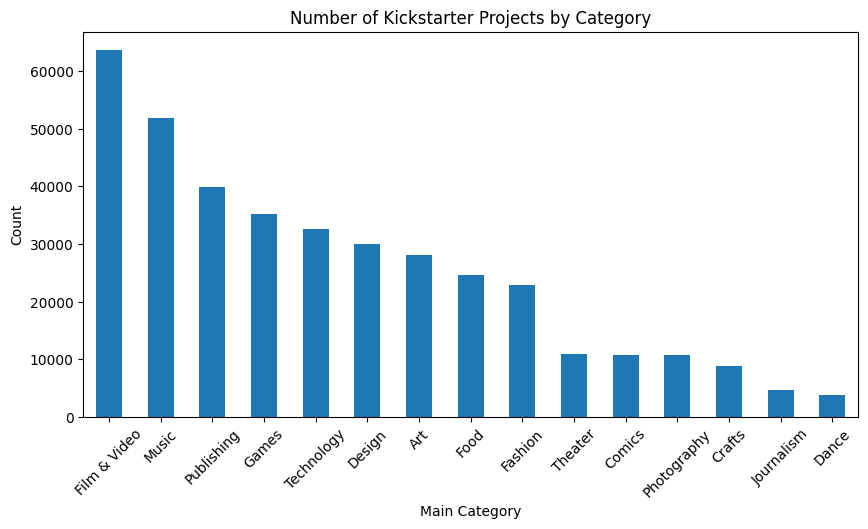

In [9]:
import matplotlib.pyplot as plt

df['main_category'].value_counts().plot(kind='bar', figsize=(10,5))
plt.title('Number of Kickstarter Projects by Category')
plt.xlabel('Main Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [11]:
missing_count = df['usd pledged'].isnull().sum()
total_count = len(df)
missing_percentage = (missing_count / total_count) * 100

print(f"Number of missing values in 'usd pledged': {missing_count}")
print(f"Percentage of missing values: {missing_percentage:.2f}%")

Number of missing values in 'usd pledged': 3797
Percentage of missing values: 1.00%


In [12]:
# Filter dataset to focus on completed projects (successful and failed)
completed_projects = df[df['state'].isin(['successful', 'failed'])]

# Create a cross-tabulation table with percentages
category_success = pd.crosstab(completed_projects['main_category'], completed_projects['state'], normalize='index') * 100
category_success = category_success.sort_values(by='successful', ascending=False)

display(category_success)

state,failed,successful
main_category,,
Dance,34.564791,65.435209
Theater,36.203866,63.796134
Comics,40.858473,59.141527
Music,47.339442,52.660558
Art,55.110955,44.889045
Games,56.109533,43.890467
Film & Video,58.209351,41.790649
Design,58.405614,41.594386
Publishing,65.298350,34.701650


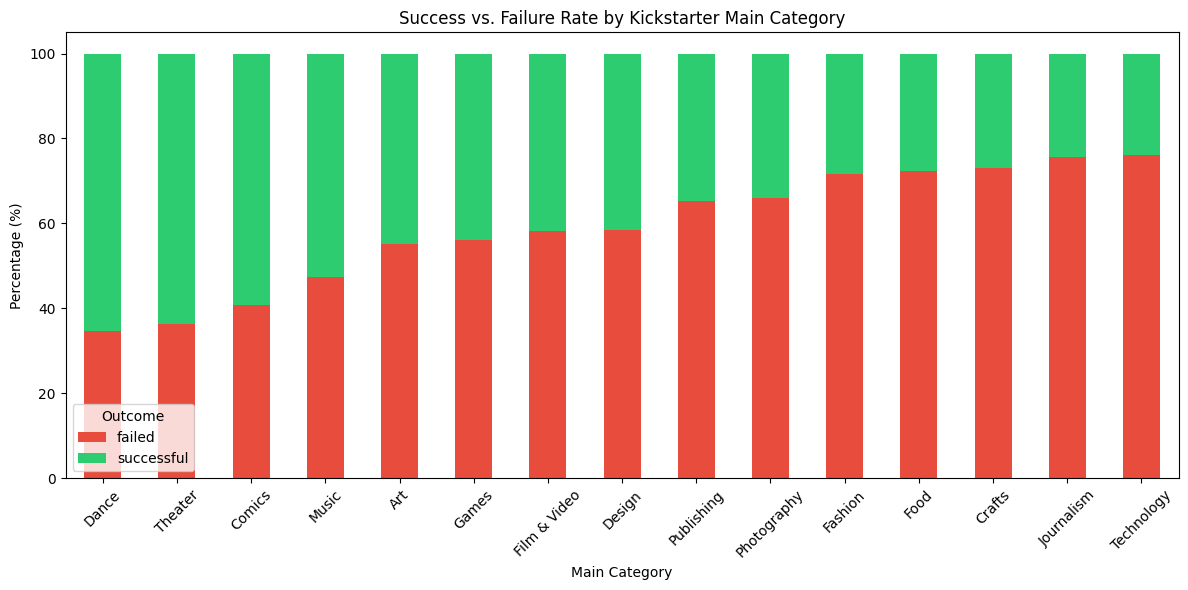

In [13]:
# Visualize the success/failure rate by main category
category_success.plot(kind='bar', stacked=True, figsize=(12, 6), color=['#e74c3c', '#2ecc71'])
plt.title('Success vs. Failure Rate by Kickstarter Main Category')
plt.xlabel('Main Category')
plt.ylabel('Percentage (%)')
plt.legend(title='Outcome', loc='lower left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
import scipy.stats as stats

# Create a contingency table (cross-tabulation of counts)
contingency_table = pd.crosstab(completed_projects['main_category'], completed_projects['state'])

print("Contingency Table:")
display(contingency_table)

# Perform the Chi-Square test of independence
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print(f"\nChi-Square Statistic: {chi2:.2f}")
print(f"Degrees of Freedom: {dof}")
print(f"P-value: {p_value}")

# Interpret the results
alpha = 0.05
if p_value < alpha:
    print("\nDecision: Reject the null hypothesis (H0).")
    print("Conclusion: There is a statistically significant association between a project's main category and its likelihood of success.")
else:
    print("\nDecision: Fail to reject the null hypothesis (H0).")
    print("Conclusion: There is no statistically significant association between a project's main category and its likelihood of success.")

Contingency Table:


state,failed,successful
main_category,,
Art,14131,11510
Comics,4036,5842
Crafts,5703,2115
Dance,1235,2338
Design,14814,10550
Fashion,14182,5593
Film & Video,32904,23623
Food,15969,6085
Games,16003,12518



Chi-Square Statistic: 15455.44
Degrees of Freedom: 14
P-value: 0.0

Decision: Reject the null hypothesis (H0).
Conclusion: There is a statistically significant association between a project's main category and its likelihood of success.
